<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

# Day 6 · Vintage — The Night of the Great Flood
### #30DayMapChallenge 2026 · ERA5 · Map by Matthias Aengenheyster

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

On the night of **31 January 1953** a depression crossed the North Sea and drove a storm
surge into the closing funnel between England and the Netherlands. More than **2,500 people
died**. It remains the deadliest natural disaster in modern Dutch and British history, and
it is the reason the Delta Works and the Thames Barrier exist.

This is that night drawn as the charts of the day were drawn — **isobars, wind barbs, fronts,
ink on paper**. The inversion is the point: the analysis underneath is **ERA5**, a reanalysis
produced seventy years later, which reconstructs 1953 in more detail than any forecaster
of 1953 could see. The map looks like the past; the data is emphatically the present.

## Method

- **The field:** ERA5 mean sea level pressure and 10 m wind for **31 Jan 1953, 18:00 UTC** —
  the hour the low sat over the German Bight and the northerly gale was fully established
  behind it. ERA5 now runs back to **1940**, so the pre-satellite era is in reach.
- **Isobars** every 4 hPa, the period interval, lightly smoothed and drawn with matplotlib's
  `path.sketch` wobble so the lines read as pen rather than plot.
- **Wind** in knots as standard barbs on a coarse grid — the station-model texture of a real chart.
- **Fronts** from the **850 hPa equivalent potential temperature** (θₑ) gradient. For each
  latitude the ridge of |∇θₑ| is found inside a longitude window, a 3-point median removes
  single-latitude jumps, and a spline smooths the result. Each band is classified by the sign
  of the thermal advection **−v·∇θₑ**.
- **Only cold fronts appear, and that is the story.** By 18h the storm was **occluded**: the
  warm sector had been pinched out, both θₑ bands show cold advection, and what was left was a
  cold northerly gale blowing straight down a sea that narrows to the south. That is precisely
  the configuration that builds a surge.
- **The depression's track** (dotted) is the MSLP minimum every 3 h from 31 Jan 00h to 1 Feb 21h.

## Licence & attribution

**ERA5** is produced by **ECMWF** for the **Copernicus Climate Change Service (C3S)** and
distributed through the Copernicus Climate Data Store. Coastlines are **Natural Earth** (public domain).

`Contains modified Copernicus Climate Change Service information [1953]`  ·  `© ECMWF`

Neither the European Commission nor ECMWF is responsible for any use of the Copernicus information here.

## Tools

| Tool | Role |
|---|---|
| [`cdsapi`](https://cds.climate.copernicus.eu/how-to-api) | fetch ERA5 single-level and pressure-level fields from the CDS |
| [`xarray`](https://docs.xarray.dev) · [`scipy`](https://scipy.org) | read the fields; smooth, differentiate and trace the thermal ridge |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`matplotlib`](https://matplotlib.org) | Lambert conformal projection, isobars, barbs, front symbols, paper |

```bash
pip install cdsapi xarray netcdf4 scipy cartopy matplotlib
```

**Learn more:** [ERA5 (CDS)](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)  ·  [ERA5 back extension to 1940](https://confluence.ecmwf.int/display/CKB/ERA5)  ·  [#30DayMapChallenge](https://30daymapchallenge.com/)

### Configuration

In [1]:
import os
WHEN   = "1953-01-31T18:00"              # the hour of the chart
AREA   = [66, -25, 44, 20]               # N, W, S, E — retrieval box
EXTENT = [-13, 17, 46.5, 63.5]           # the chart frame
NC_SFC, NC_PL = "data/era5_1953_sfc.nc", "data/era5_1953_pl.nc"
OUT = "day06_vintage_1953.png"

# the palette of an old printed chart
PAPER, INK, FADE = "#e9ddc1", "#2a2018", "#6f6150"
COLDC, WARMC = "#1f3d6b", "#8b2436"
AUTHOR = "Matthias Aengenheyster"
os.makedirs("data", exist_ok=True)

## Retrieve — ERA5 from the Copernicus Climate Data Store

Two requests: surface pressure and wind for the chart itself, 850 hPa temperature and
humidity for the fronts. Needs a [CDS account and `~/.cdsapirc`](https://cds.climate.copernicus.eu/how-to-api).
Both files are small (a few MB) — the area is clipped and the window is two days.

In [2]:
HOURS = [f"{h:02d}:00" for h in range(0, 24, 3)]

if not os.path.exists(NC_SFC):
    import cdsapi
    cdsapi.Client().retrieve("reanalysis-era5-single-levels", {
        "product_type": ["reanalysis"],
        "variable": ["mean_sea_level_pressure", "10m_u_component_of_wind",
                     "10m_v_component_of_wind"],
        "year": ["1953"], "month": ["01", "02"], "day": ["31", "01"],
        "time": HOURS, "area": AREA,
        "data_format": "netcdf", "download_format": "unarchived",
    }, NC_SFC)

if not os.path.exists(NC_PL):
    import cdsapi
    cdsapi.Client().retrieve("reanalysis-era5-pressure-levels", {
        "product_type": ["reanalysis"],
        "variable": ["temperature", "specific_humidity"],
        "pressure_level": ["850"],
        "year": ["1953"], "month": ["01", "02"], "day": ["31", "01"],
        "time": HOURS, "area": AREA,
        "data_format": "netcdf", "download_format": "unarchived",
    }, NC_PL)

print("have ERA5 surface + 850 hPa")

have ERA5 surface + 850 hPa


## Read the fields and derive the thermal structure

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, xarray as xr
from scipy.ndimage import gaussian_filter, median_filter, minimum_filter, maximum_filter

sfA = xr.open_dataset(NC_SFC)                     # all times, for the track
sf  = sfA.sel(valid_time=WHEN)
pl  = xr.open_dataset(NC_PL).sel(valid_time=WHEN)

lon, lat = sf.longitude.values, sf.latitude.values
msl = gaussian_filter(sf.msl.values / 100.0, 1.2)             # hPa
u, v = sf.u10.values * 1.94384, sf.v10.values * 1.94384       # knots

# equivalent potential temperature at 850 hPa
T, q = pl.t.squeeze().values, pl.q.squeeze().values
theta_e = gaussian_filter(T * (1000 / 850) ** 0.286 * np.exp(2.5e6 * q / (1004 * T)), 2.5)

# horizontal gradient on the lat/lon grid, in K per metre
R = 6.371e6
dlo, dla = np.gradient(lon)[0] * np.pi / 180, np.gradient(lat)[0] * np.pi / 180
coslat = np.cos(np.deg2rad(lat))[:, None]
gy, gx = np.gradient(theta_e)
dthe_dx, dthe_dy = gx / (R * coslat * dlo), gy / (R * dla)
grad = gaussian_filter(np.hypot(dthe_dx, dthe_dy), 2.0)
adv  = -(sf.u10.values * dthe_dx + sf.v10.values * dthe_dy)    # thermal advection

print(f"MSLP {msl.min():.1f}–{msl.max():.1f} hPa   "
      f"|grad theta-e| max {grad.max()*1e5:.1f} K/100km")

MSLP 972.5–1032.0 hPa   |grad theta-e| max 7.4 K/100km


### Trace the frontal bands

Follow the ridge of |∇θₑ| latitude by latitude inside a longitude window, median-filter out
single-latitude jumps, and classify by the sign of the advection. Two bands survive in the
frame: one curving down the North Sea west of the low, one over the eastern Baltic approaches.
**Both are cold** — the signature of an occluded storm with no warm sector left.

In [4]:
def trace_band(lat_from, lat_to, lon_lo, lon_hi, step=1.0):
    """Ridge of |grad theta-e| by latitude, inside a longitude window."""
    pts = []
    for La in np.arange(lat_from, lat_to - 1e-9, -step):
        j = int(np.argmin(np.abs(lat - La)))
        i0, i1 = sorted((int(np.argmin(np.abs(lon - lon_lo))),
                         int(np.argmin(np.abs(lon - lon_hi)))))
        k = i0 + int(np.argmax(grad[j, i0:i1 + 1]))
        pts.append((lon[k], lat[j], grad[j, k], adv[j, k]))
    P = np.array(pts)
    P[:, 0] = median_filter(P[:, 0], size=3, mode="nearest")   # de-spike
    return P

BANDS = []
for name, (a, b, lo, hi) in {"North Sea": (61, 52, -4, 4),
                             "Baltic approaches": (56, 49, 5, 16)}.items():
    P = trace_band(a, b, lo, hi)
    kind = "warm" if P[:, 3].mean() > 0 else "cold"
    BANDS.append((P[:, :2], kind))
    print(f"{name:20s} |grad| {P[:,2].mean()*1e5:.1f} K/100km -> {kind} front")

North Sea            |grad| 4.2 K/100km -> cold front
Baltic approaches    |grad| 4.2 K/100km -> cold front


## Draw the chart

saved day06_vintage_1953.png


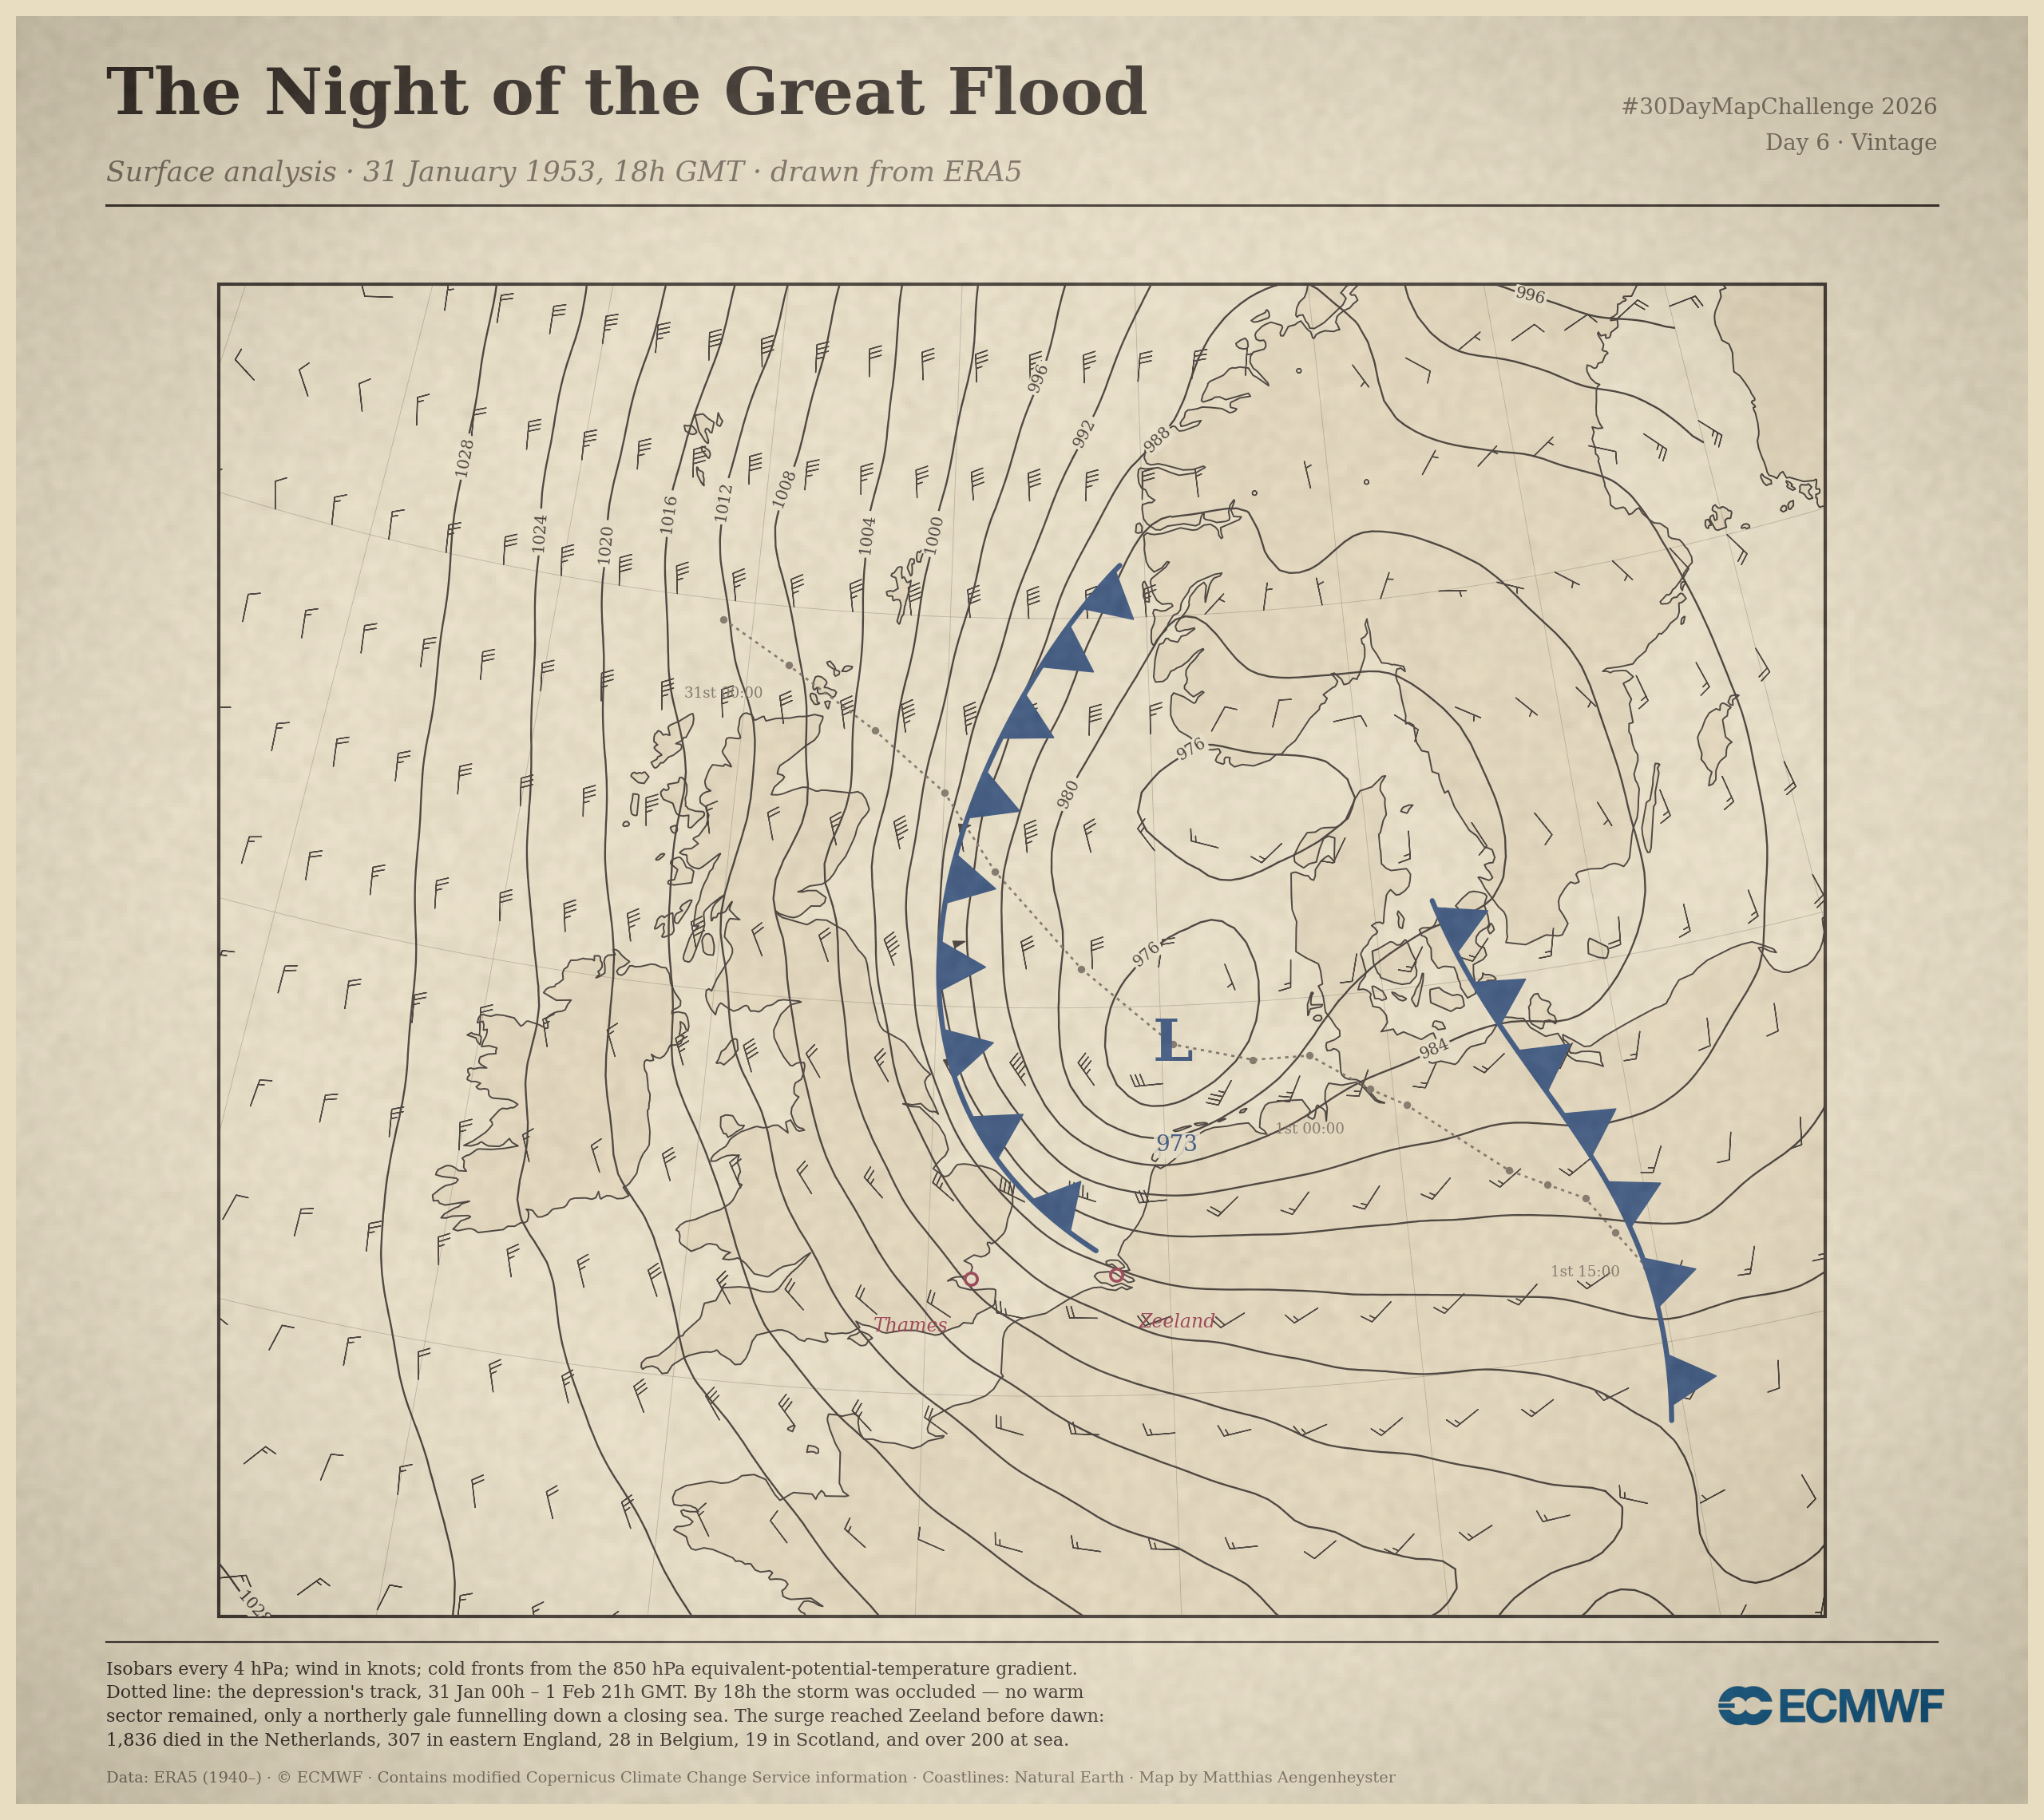

In [5]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.patches import Polygon, Wedge
import cartopy.crs as ccrs, cartopy.feature as cfeature
from scipy.interpolate import splprep, splev

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Georgia", "Palatino", "DejaVu Serif"]
proj = ccrs.LambertConformal(central_longitude=2.5, central_latitude=55,
                             standard_parallels=(45, 62))
PC = ccrs.PlateCarree()

fig = plt.figure(figsize=(12.6, 11.2), dpi=200); fig.patch.set_facecolor(PAPER)
ax = fig.add_axes([0.045, 0.105, 0.91, 0.745], projection=proj)
ax.set_extent(EXTENT, PC); ax.set_facecolor(PAPER)
ax.spines["geo"].set_edgecolor(INK); ax.spines["geo"].set_linewidth(1.5)

ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#e2d4b4", zorder=0)
ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=PAPER, zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, linewidth=0.7, zorder=3)
ax.gridlines(linewidth=0.3, color=FADE, alpha=0.45,
             xlocs=range(-30, 31, 5), ylocs=range(40, 71, 5), zorder=1)

# --- isobars every 4 hPa, with a pen-and-ink wobble
cs = ax.contour(lon, lat, msl, levels=np.arange(920, 1081, 4), colors=INK,
                linewidths=0.85, transform=PC, zorder=4)
try: arts = cs.collections
except AttributeError: arts = [cs]
for a in arts: a.set_sketch_params(1.3, 190, 3)
for t in ax.clabel(cs, inline=True, fmt="%d", fontsize=7.2, colors=INK, inline_spacing=4):
    t.set_bbox(dict(fc=PAPER, ec="none", pad=0.5))

# --- wind barbs, knots
st = 6
ax.barbs(lon[::st], lat[::st], u[::st, ::st], v[::st, ::st], length=5.0, linewidth=0.5,
         color=INK, transform=PC, zorder=5,
         sizes=dict(emptybarb=0.08, spacing=0.17, height=0.42))

# --- front symbols: triangles (cold) / semicircles (warm) on the warm-air side
def theta_at(lo, la):
    i = int(np.clip(np.searchsorted(lon, lo), 0, len(lon) - 1))
    j = int(np.clip(np.argmin(np.abs(lat - la)), 0, len(lat) - 1))
    return theta_e[j, i]

def draw_front(pts, kind, n=9, smooth=3.0, h=70e3):
    tck, _ = splprep([pts[:, 0], pts[:, 1]], s=smooth, k=3)
    fl, fa = splev(np.linspace(0, 1, 260), tck)
    XY = proj.transform_points(PC, np.asarray(fl), np.asarray(fa))[:, :2]
    ax.plot(XY[:, 0], XY[:, 1], color=COLDC, lw=2.3, zorder=7, solid_capstyle="round")
    for i in np.linspace(14, len(XY) - 15, n).astype(int):
        t = XY[i + 6] - XY[i - 6]; t /= np.hypot(*t)
        nrm = np.array([-t[1], t[0]])
        side = [theta_at(*PC.transform_point(*(XY[i] + s * nrm * 90e3), proj)) for s in (1, -1)]
        nn = nrm if side[0] >= side[1] else -nrm          # point into the warm air
        if kind == "cold":
            ax.add_patch(Polygon(np.array([XY[i] - t*h*0.52, XY[i] + t*h*0.52,
                                           XY[i] + nn*h*0.95]), closed=True,
                                 fc=COLDC, ec=COLDC, lw=0.5, zorder=8))
        else:
            ang = np.degrees(np.arctan2(nn[1], nn[0]))
            ax.add_patch(Wedge(XY[i], h*0.52, ang-90, ang+90, fc=COLDC, ec=COLDC,
                               lw=0.5, zorder=8))

for pts, kind in BANDS:
    draw_front(pts, kind, n=9 if len(pts) > 8 else 7)

# --- pressure centres, deepest first so the dedupe keeps the real one
def centres(F, kind, size=18, prom=1.5, sep=6.0):
    flt = minimum_filter(F, size) if kind == "L" else maximum_filter(F, size)
    yy, xx = np.where(F == flt)
    order = np.argsort([F[j, i] for j, i in zip(yy, xx)])
    if kind == "H": order = order[::-1]
    out = []
    for j, i in zip(yy[order], xx[order]):
        lo, la = lon[i], lat[j]
        if not (EXTENT[0]+1.5 < lo < EXTENT[1]-1.5 and EXTENT[2]+1.5 < la < EXTENT[3]-1.5):
            continue
        w = F[max(0, j-18):j+19, max(0, i-18):i+19]
        if (w.max() - F[j, i] if kind == "L" else F[j, i] - w.min()) < prom: continue
        if any(np.hypot(lo-o[0], la-o[1]) < sep for o in out): continue
        out.append((lo, la, F[j, i]))
    return out

for kind, col in (("L", COLDC), ("H", INK)):
    for lo, la, p in centres(msl, kind):
        ax.text(lo, la, kind, transform=PC, ha="center", va="center", fontsize=26,
                fontweight="bold", color=col, zorder=9)
        ax.text(lo, la - 1.3, f"{p:.0f}", transform=PC, ha="center", va="center",
                fontsize=10, color=col, zorder=9,
                bbox=dict(fc=PAPER, ec="none", pad=0.9, alpha=0.85))

# --- the depression's track
tr = []
for tt in sfA.valid_time.values:
    s = str(tt)[:16]
    if not s.startswith(("1953-01-31", "1953-02-01")): continue
    m = gaussian_filter(sfA.msl.sel(valid_time=tt).values / 100, 1.2)
    j = np.unravel_index(np.nanargmin(m), m.shape)
    tr.append((lon[j[1]], lat[j[0]], s[11:16]))
TX = proj.transform_points(PC, np.array([p[0] for p in tr]), np.array([p[1] for p in tr]))[:, :2]
ax.plot(TX[:, 0], TX[:, 1], ls=(0, (1.5, 2)), lw=1.0, color=FADE, zorder=6)
ax.plot(TX[:, 0], TX[:, 1], "o", ms=2.4, color=FADE, zorder=6, ls="none")
for k in (0, 8, 13):
    lo, la, hh = tr[k]
    ax.text(*(proj.transform_point(lo, la, PC) + np.array([0, -95e3])),
            ("31st " if k < 8 else "1st ") + hh, ha="center", va="top",
            fontsize=6.6, color=FADE, zorder=6)

# --- the two coasts the surge broke
for lo, la, lb, ha in [(0.9, 51.5, "Thames", "right"), (3.9, 51.55, "Zeeland", "left")]:
    ax.plot(lo, la, marker="o", ms=5.5, mfc="none", mec=WARMC, mew=1.3, transform=PC, zorder=9)
    ax.text(lo + (0.45 if ha == "left" else -0.45), la - 0.5, lb, transform=PC,
            ha=ha, va="top", fontsize=8.5, color=WARMC, style="italic", zorder=9)

# --- header, caption, attribution
fig.text(0.045, 0.945, "The Night of the Great Flood", fontsize=29, color=INK, fontweight="bold")
fig.text(0.045, 0.908, "Surface analysis \u00b7 31 January 1953, 18h GMT \u00b7 drawn from ERA5",
         fontsize=12.5, color=FADE, style="italic")
fig.text(0.955, 0.945, "#30DayMapChallenge 2026", fontsize=10, color=FADE, ha="right")
fig.text(0.955, 0.925, "Day 6 \u00b7 Vintage", fontsize=10, color=FADE, ha="right")
for y, lw in ((0.894, 1.1), (0.0905, 0.8)):
    fig.lines.append(plt.Line2D([0.045, 0.955], [y, y], transform=fig.transFigure, color=INK, lw=lw))
fig.text(0.045, 0.080,
    "Isobars every 4 hPa; wind in knots; cold fronts from the 850 hPa equivalent-potential-temperature gradient.\n"
    "Dotted line: the depression's track, 31 Jan 00h \u2013 1 Feb 21h GMT. By 18h the storm was occluded \u2014 no warm\n"
    "sector remained, only a northerly gale funnelling down a closing sea. The surge reached Zeeland before dawn:\n"
    "1,836 died in the Netherlands, 307 in eastern England, 28 in Belgium, 19 in Scotland, and over 200 at sea.",
    fontsize=8.0, color=INK, va="top", linespacing=1.45)
fig.text(0.045, 0.012, f"Data: ERA5 (1940\u2013) \u00b7 \u00a9 ECMWF \u00b7 Contains modified Copernicus Climate "
         f"Change Service information \u00b7 Coastlines: Natural Earth \u00b7 Map by {AUTHOR}",
         fontsize=7, color=FADE)
try:
    la_ = fig.add_axes([0.846, 0.030, 0.112, 0.050]); la_.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); la_.axis("off")
except FileNotFoundError:
    pass

# --- paper grain and a soft vignette, laid over the print
rng = np.random.default_rng(1953)
ta = fig.add_axes([0, 0, 1, 1], zorder=20); ta.axis("off"); ta.patch.set_alpha(0)
ta.imshow(gaussian_filter(rng.random((520, 600)), 1.1), cmap="Greys", alpha=0.075,
          extent=[0, 1, 0, 1], aspect="auto")
yy, xx = np.mgrid[0:520, 0:600]
ta.imshow(np.clip(np.hypot((xx-300)/300, (yy-260)/260) - 0.75, 0, None), cmap="Greys",
          alpha=0.16, extent=[0, 1, 0, 1], aspect="auto")
ta.set_xlim(0, 1); ta.set_ylim(0, 1)

fig.savefig(OUT, facecolor=PAPER)
print("saved", OUT)

## Note

ERA5's back extension reaches **1940**, so the whole pre-satellite era can be re-analysed with a
modern model and modern assimilation. The 1953 chart that forecasters actually worked from was
drawn by hand from a sparse network of ships and coastal stations, under a deadline, at night.
They saw the depression; what they could not see was how fast the surge was building behind it,
and there was no warning system to pass on if they had.

The map is deliberately old-looking and the analysis underneath is deliberately not. Both halves
matter: the data has got better by a margin that is hard to show on a single chart, and the flood
defences built after this night — the Delta Works, the Thames Barrier — were the other half of the
answer. Figure saved as `day06_vintage_1953.png`.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*